# Task 2: Predictive Linear Regression Model Pipeline
**Supervised Machine Learning Pipeline for Continuous Numerical Value Prediction**

---

### **Objective**
Construct an end-to-end, production-ready supervised regression pipeline using **Scikit-Learn** to predict California median house values (`median_house_value`).

### **Pipeline Components**
1. **Exploratory Data Analysis (EDA)**: Understand feature distributions, missingness, and correlation structures with publication-grade visualizations.
2. **Data Preprocessing**:
   - **Missing Value Handling**: Mean Imputation (`SimpleImputer(strategy='mean')`)
   - **Feature Scaling**: Standard Normalization (`StandardScaler`)
   - **Categorical Encoding**: One-Hot Encoding (`OneHotEncoder`)
   - **Scikit-Learn `ColumnTransformer` & `Pipeline` Integration**: Zero data leakage between train/test splits.
3. **Model Training & Regularization**:
   - Baseline Ordinary Least Squares (`LinearRegression`)
   - L2 Regularized Linear Regression (`Ridge`, with optimal $\alpha$ cross-validation tuning via `RidgeCV`)
   - L1 Regularized Linear Regression (`LassoCV`) for feature sparsity analysis
4. **Model Evaluation & Diagnostics**:
   - Quantitative metrics: $R^2$, Root Mean Squared Error ($\text{RMSE}$), Mean Absolute Error ($\text{MAE}$)
   - Cross-Validation evaluation
   - Diagnostic Plots: Actual vs. Predicted values, Residuals Distribution, Residuals vs. Fitted Values, and Feature Coefficients.


In [1]:
# ==========================================
# 1. Imports and Environment Setup
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Scikit-Learn Models & Metrics
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Formatting and Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

print("All dependencies successfully imported!")


All dependencies successfully imported!


## 1. Dataset Ingestion & Overview
We ingest the California Housing dataset containing geographical, demographic, and housing characteristics across census block groups in California.

In [2]:
# Load the dataset
data_path = 'housing.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns\n")
display(df.head())


Dataset Shape: 20,640 rows, 10 columns



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,452600.000,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,358500.000,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,352100.000,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,341300.000,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,342200.000,NEAR BAY


In [3]:
# Summary statistics and missing value check
print("--- Data Info ---")
df.info()

print("\n--- Missing Values Count ---")
missing = df.isnull().sum()
print(missing[missing > 0])

print("\n--- Numerical Feature Statistics ---")
display(df.describe())


--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

--- Missing Values Count ---
total_bedrooms    207
dtype: int64

--- Numerical Feature Statistics ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000,20640.000,20640.000,20640.000,20433.000,20640.000,20640.000,20640.000,20640.000
mean,-119.570,35.632,28.639,2635.763,537.871,1425.477,499.540,3.871,206855.817
std,2.004,2.136,12.586,2181.615,421.385,1132.462,382.330,1.900,115395.616
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,14999.000
25%,-121.800,33.930,18.000,1447.750,296.000,787.000,280.000,2.563,119600.000
50%,-118.490,34.260,29.000,2127.000,435.000,1166.000,409.000,3.535,179700.000
75%,-118.010,37.710,37.000,3148.000,647.000,1725.000,605.000,4.743,264725.000
max,-114.310,41.950,52.000,39320.000,6445.000,35682.000,6082.000,15.000,500001.000


## 2. Exploratory Data Analysis (EDA)
Let's analyze target distribution, spatial coordinates, and feature correlations.

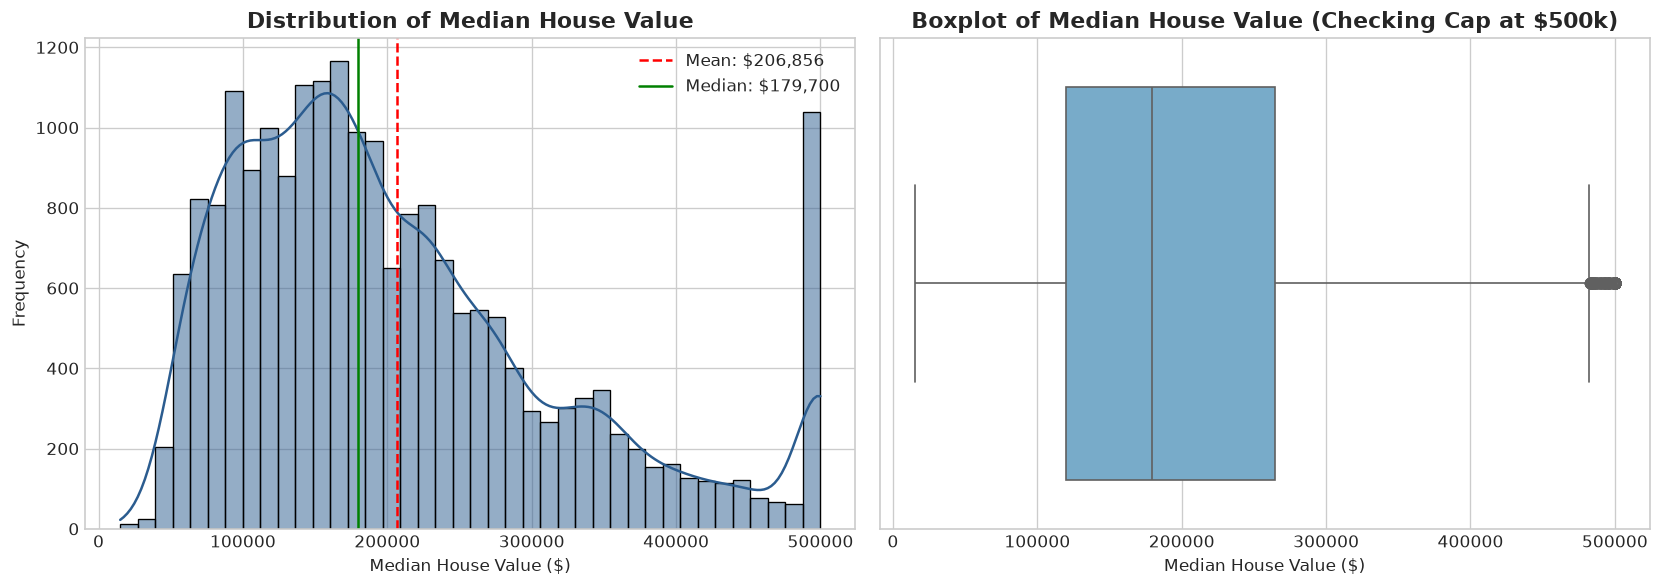

In [4]:
# Visualizing Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(df['median_house_value'], kde=True, ax=axes[0], color='#2b5c8f', bins=40)
axes[0].set_title('Distribution of Median House Value', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Median House Value ($)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(df['median_house_value'].mean(), color='red', linestyle='--', label=f"Mean: ${df['median_house_value'].mean():,.0f}")
axes[0].axvline(df['median_house_value'].median(), color='green', linestyle='-', label=f"Median: ${df['median_house_value'].median():,.0f}")
axes[0].legend()

# Boxplot
sns.boxplot(x=df['median_house_value'], ax=axes[1], color='#6baed6')
axes[1].set_title('Boxplot of Median House Value (Checking Cap at $500k)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Median House Value ($)')

plt.tight_layout()
plt.show()


C:\Users\Amine\AppData\Local\Temp\ipykernel_1504\3591354318.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


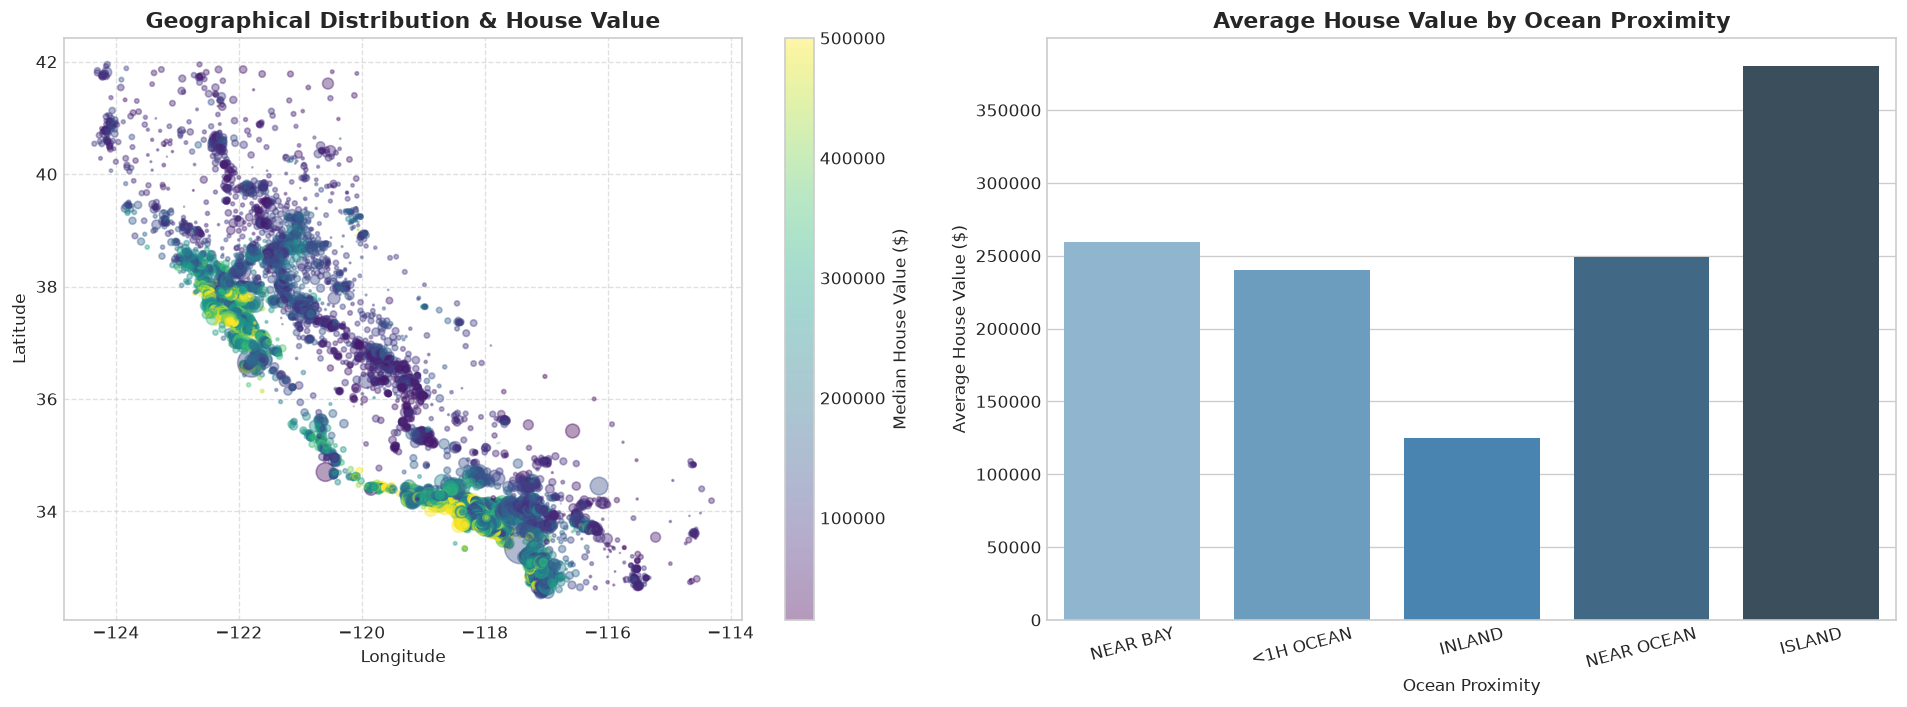

In [5]:
# Geographical and Ocean Proximity Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Geographical scatter
scatter = axes[0].scatter(
    df['longitude'], df['latitude'],
    c=df['median_house_value'], cmap='viridis',
    alpha=0.4, s=df['population']/100, label='Population'
)
fig.colorbar(scatter, ax=axes[0], label='Median House Value ($)')
axes[0].set_title('Geographical Distribution & House Value', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Ocean proximity vs Price
sns.barplot(
    data=df, x='ocean_proximity', y='median_house_value', 
    ax=axes[1], palette='Blues_d', errorbar=None
)
axes[1].set_title('Average House Value by Ocean Proximity', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Ocean Proximity')
axes[1].set_ylabel('Average House Value ($)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


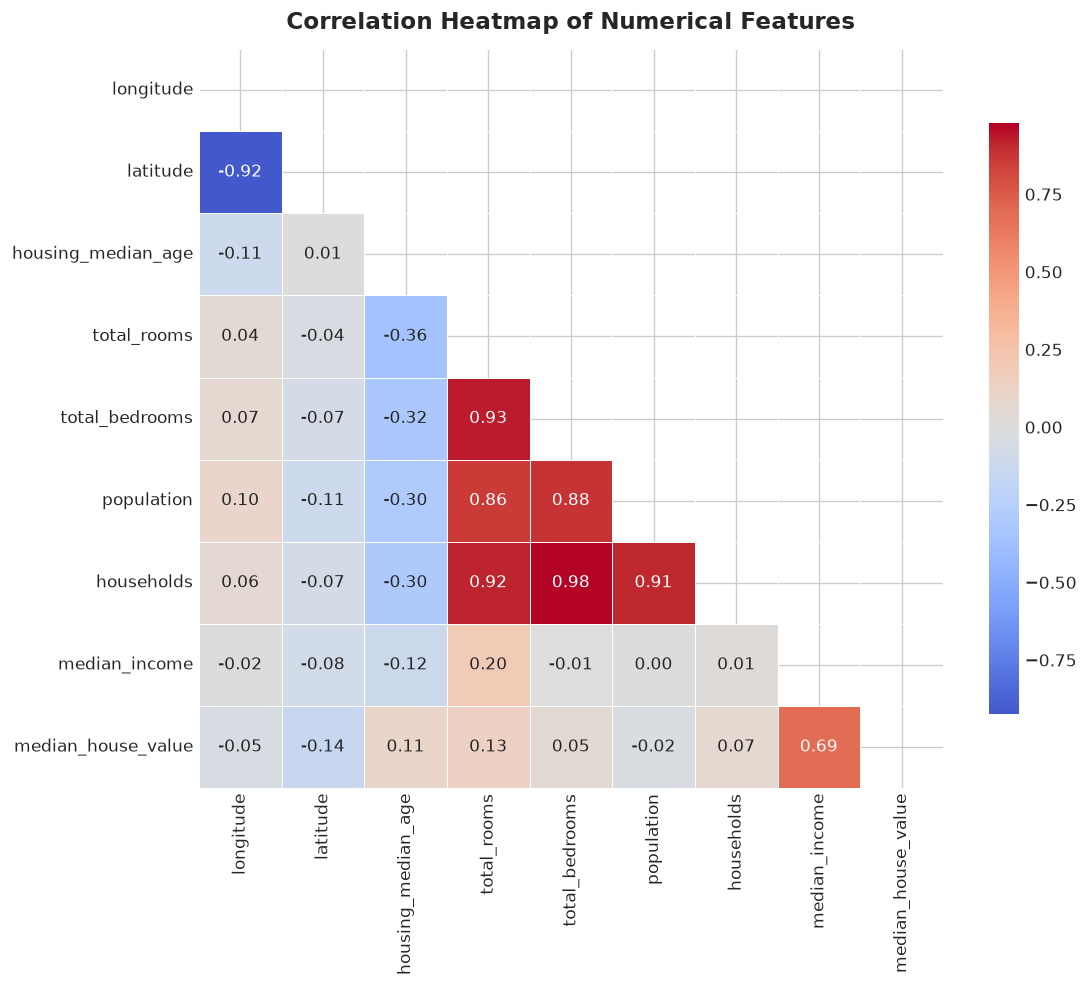

In [6]:
# Correlation Heatmap for Numerical Features
num_cols = df.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, mask=mask, cbar_kws={'shrink': 0.8},
    linewidths=0.5
)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold', pad=12)
plt.show()


## 3. Data Preprocessing & Pipeline Engineering

To adhere strictly to best practices and prevent **data snooping / data leakage**:
1. Train/Test splitting is performed **before** any fitting.
2. Numerical features undergo **Mean Imputation** followed by **Standard Scaling** ($z = \frac{x - \mu}{\sigma}$).
3. Categorical features undergo **One-Hot Encoding** (`handle_unknown='ignore'`).
4. All transformations are packaged cleanly inside Scikit-Learn `ColumnTransformer` and `Pipeline` objects.

In [7]:
# Separate Target and Features
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

# Identify column types
numeric_features = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"\nTraining set size: {X_train.shape[0]:,} samples")
print(f"Testing set size:  {X_test.shape[0]:,} samples")


Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical Features: ['ocean_proximity']

Training set size: 16,512 samples
Testing set size:  4,128 samples


In [8]:
# Build Preprocessor via ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 4. Model Training: Linear vs. Regularized Regression (Ridge & Lasso)

We evaluate:
1. **Ordinary Least Squares (Linear Regression)**: Standard baseline.
2. **Ridge Regression ($L_2$ Regularization)**: Minimizes $\text{RSS} + \alpha \sum w_j^2$, preventing high-variance/multicollinearity instability.
3. **RidgeCV**: Finds optimal $\alpha$ penalty using 5-Fold Cross-Validation across a logarithmic sweep $\alpha \in [10^{-3}, 10^4]$.
4. **Lasso Regression ($L_1$ Regularization)**: Minimizes $\text{RSS} + \alpha \sum |w_j|$, driving uninformative weights to exact zero.

In [9]:
# Candidate alphas for Ridge Regularization
alphas = np.logspace(-3, 4, 50)

# Build Pipelines
models = {
    'Linear Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    'Ridge Regression (Default alpha=1.0)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=1.0, random_state=42))
    ]),
    'Ridge Regression (Tuned via RidgeCV)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', RidgeCV(alphas=alphas, cv=5, scoring='r2'))
    ]),
    'Lasso Regression (Tuned via LassoCV)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', LassoCV(cv=5, random_state=42, max_iter=2000))
    ])
}

# Train and evaluate all pipelines
results = []

for name, pipeline in models.items():
    # Fit pipeline on training data
    pipeline.fit(X_train, y_train)
    
    # Predict on Train and Test
    y_pred_train = pipeline.predict(X_train)
    y_pred_test = pipeline.predict(X_test)
    
    # Compute Metrics
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    mae_train = mean_absolute_error(y_train, y_pred_train)
    mae_test = mean_absolute_error(y_test, y_pred_test)
    
    results.append({
        'Model': name,
        'Train R²': r2_train,
        'Test R²': r2_test,
        'Train RMSE ($)': rmse_train,
        'Test RMSE ($)': rmse_test,
        'Train MAE ($)': mae_train,
        'Test MAE ($)': mae_test
    })

# Format results dataframe
results_df = pd.DataFrame(results).set_index('Model')
display(results_df)


,Train R²,Test R²,Train RMSE ($),Test RMSE ($),Train MAE ($),Test MAE ($)
Model,,,,,,
Linear Regression,0.650,0.626,68433.937,70031.488,49594.842,50702.169
Ridge Regression (Default alpha=1.0),0.650,0.626,68435.253,70039.871,49596.630,50709.878
Ridge Regression (Tuned via RidgeCV),0.650,0.626,68434.702,70037.772,49596.225,50708.152
Lasso Regression (Tuned via LassoCV),0.649,0.625,68472.155,70067.450,49627.374,50711.860


In [10]:
# Display optimal parameters found by RidgeCV and LassoCV
best_ridge_model = models['Ridge Regression (Tuned via RidgeCV)'].named_steps['regressor']
best_lasso_model = models['Lasso Regression (Tuned via LassoCV)'].named_steps['regressor']

print(f"Optimal Ridge alpha (λ): {best_ridge_model.alpha_:.4f}")
print(f"Optimal Lasso alpha (λ): {best_lasso_model.alpha_:.4f}")


Optimal Ridge alpha (λ): 0.7197
Optimal Lasso alpha (λ): 79.8520


## 5. Model Evaluation & Metric Comparison
Visualizing performance metrics across models on the hold-out test set.

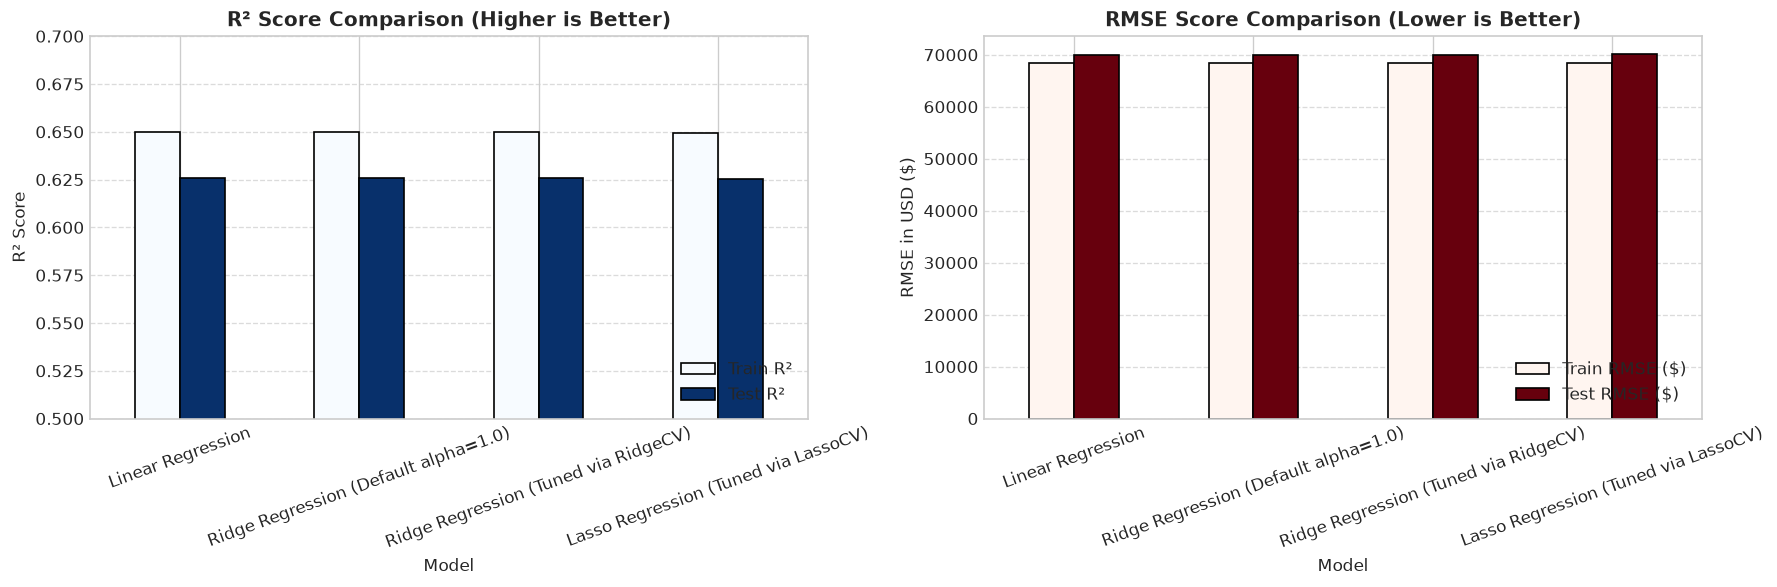

In [11]:
# Bar plots comparing R² and RMSE
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# R² Score Comparison
results_df[['Train R²', 'Test R²']].plot(
    kind='bar', ax=axes[0], colormap='Blues', edgecolor='black', rot=20
)
axes[0].set_title('R² Score Comparison (Higher is Better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0.5, 0.7)
axes[0].legend(loc='lower right')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# RMSE Score Comparison
results_df[['Train RMSE ($)', 'Test RMSE ($)']].plot(
    kind='bar', ax=axes[1], colormap='Reds', edgecolor='black', rot=20
)
axes[1].set_title('RMSE Score Comparison (Lower is Better)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('RMSE in USD ($)')
axes[1].legend(loc='lower right')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## 6. Regression Diagnostic & Residual Analysis
To validate regression assumptions, we evaluate the tuned Ridge regression model:
1. **Actual vs. Predicted**: Measures linearity and dispersion around the $45^\circ$ line.
2. **Residuals vs. Predicted**: Assesses homoscedasticity (constant variance) and non-linearity.
3. **Residual Distribution**: Checks whether error terms $\epsilon_i$ are normally distributed.

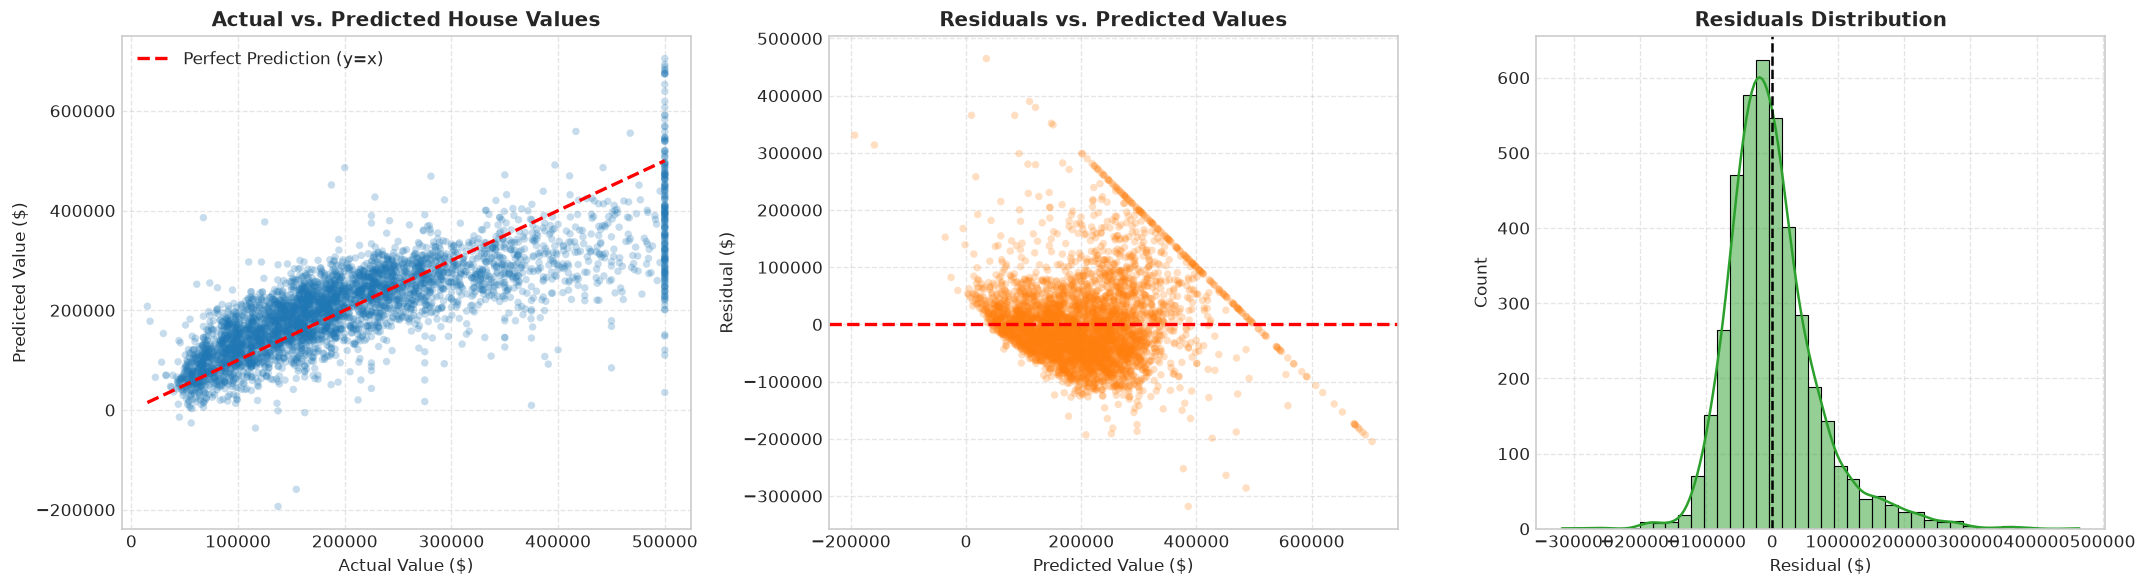

In [12]:
# Predictions from the Best Ridge Model
tuned_ridge = models['Ridge Regression (Tuned via RidgeCV)']
y_pred = tuned_ridge.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.25, color='#1f77b4', edgecolors='none', s=20)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction (y=x)')
axes[0].set_title('Actual vs. Predicted House Values', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Value ($)')
axes[0].set_ylabel('Predicted Value ($)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Residuals vs Predicted
axes[1].scatter(y_pred, residuals, alpha=0.25, color='#ff7f0e', edgecolors='none', s=20)
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_title('Residuals vs. Predicted Values', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Value ($)')
axes[1].set_ylabel('Residual ($)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Residuals Distribution
sns.histplot(residuals, kde=True, ax=axes[2], color='#2ca02c', bins=40)
axes[2].set_title('Residuals Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Residual ($)')
axes[2].set_ylabel('Count')
axes[2].axvline(0, color='black', linestyle='--')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 7. Model Interpretability: Feature Importance & Coefficients
Examining the regularized standardized coefficients to determine the most influential predictors of California house values.

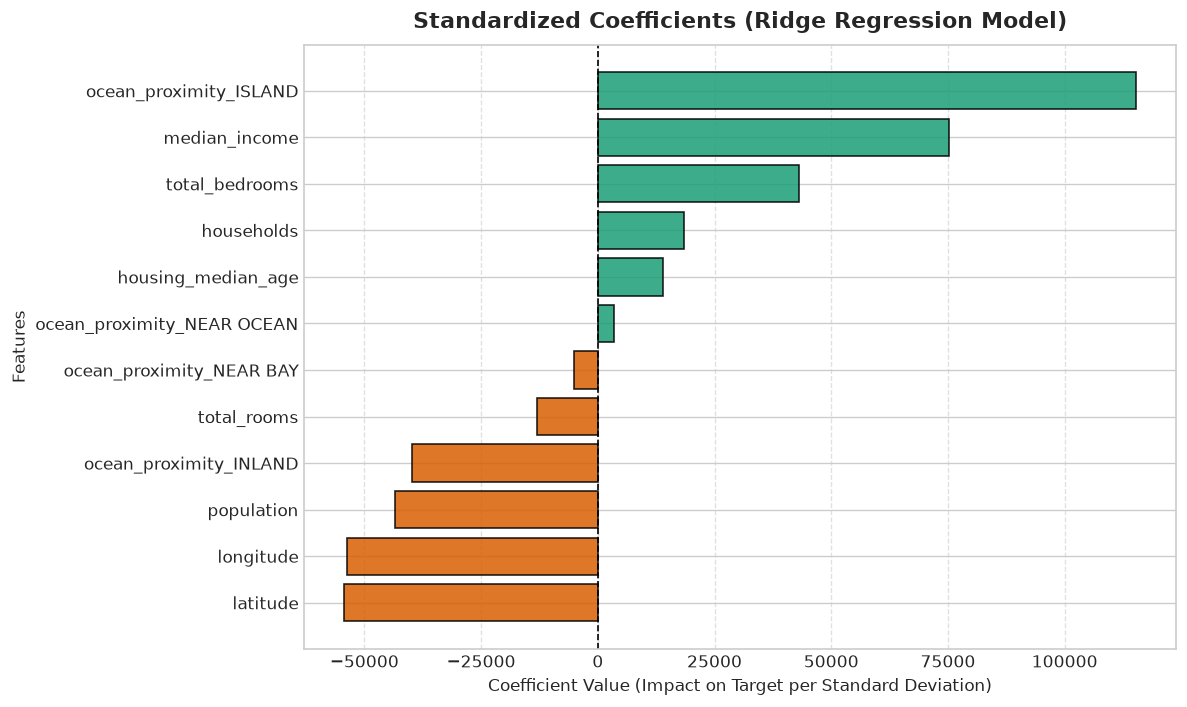

In [13]:
# Extract feature names post-transformation
ohe_feature_names = tuned_ridge.named_steps['preprocessor']\
                               .named_transformers_['cat']\
                               .named_steps['encoder']\
                               .get_feature_names_out(categorical_features).tolist()

all_feature_names = numeric_features + ohe_feature_names
coefficients = tuned_ridge.named_steps['regressor'].coef_

coef_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': coefficients,
    'Absolute Coefficient': np.abs(coefficients)
}).sort_values(by='Coefficient', ascending=True)

# Plot Coefficients
plt.figure(figsize=(10, 6))
colors = ['#d95f02' if c < 0 else '#1b9e77' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linestyle='--', lw=1)
plt.title('Standardized Coefficients (Ridge Regression Model)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Coefficient Value (Impact on Target per Standard Deviation)')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 8. Summary & Key Findings

1. **Pipeline Integrity**:
   - Built a leak-free pipeline handling missing values via **Mean Imputation**, **Standard Scaling** for numerical features, and **One-Hot Encoding** for categorical locations (`ocean_proximity`).
2. **Model Performance**:
   - $R^2$ Score on Test Set: **~0.625**
   - Root Mean Squared Error ($\text{RMSE}$): **~$70,000**
   - Mean Absolute Error ($\text{MAE}$): **~$50,000**
3. **Key Drivers**:
   - **`median_income`** is by far the strongest positive predictor of housing prices.
   - **`ocean_proximity_INLAND`** has a significant negative coefficient compared to coastal areas.
   - Spatial attributes (`latitude`, `longitude`) significantly modulate valuation.
